
---
date: "2026-10-23"
date-modified: last-modified
format:
  html:
    toc: true
---


# Fatou's Lemma and the Monotone Convergence Theorem

**Prerequisites:** [The Integral of a Nonnegative Measurable Function](lebesgue-integral.ipynb) · [Limits of Measurable Functions](limits-of-measurable-functions.ipynb) · [Continuity of Measure](continuity-of-measure.ipynb) · [The Riemann and Lebesgue Integrals of Continuous Functions](riemann-and-lebesgue-integrals.ipynb)

If measurable functions $f_n$ converge to $f$ pointwise, or even only almost everywhere, then $f$ is [measurable](limits-of-measurable-functions.ipynb#thm-pointwise-limit-measurable). Do their integrals converge to the integral of $f$? In other words, can limit and integral be interchanged,
$$\lim_{n \to \infty} \int f_n\, d\mu \overset{?}{=} \int \lim_{n \to \infty} f_n\, d\mu \;?$$
This would say that the integral is a *continuous* operation, and when it holds it is a very strong tool. In general it fails. What always holds is a one-sided inequality, **Fatou's lemma**; under extra hypotheses the interchange is valid, and the two most important such results are the **monotone convergence theorem**, proved here, and the [dominated convergence theorem](dominated-convergence-theorem.ipynb). Both follow quickly from Fatou's lemma. Throughout, $(X, \mathcal{M}, \mu)$ is a measure space.

## 1\. Mass Can Escape

::: {#exm-escape-of-mass}
## Pointwise Limits Whose Integrals Do Not Converge

All three sequences below, on $\mathbb{R}$ with Lebesgue measure, have $\int f_n\, dm = 1$ for every $n$, and converge pointwise to $f = 0$, whose integral is $0$.

1. **A moving block.** $f_n = \mathbf{1}_{[n, n+1]}$. It is simple, so $\int f_n = m([n, n+1]) = 1$. For a fixed $x$, $f_n(x) = 1$ only for the one or two $n$ with $x \in [n, n+1]$, and $f_n(x) = 0$ afterwards; so $f_n(x) \to 0$.
2. **A spreading block.** $f_n = \frac1n \mathbf{1}_{[0, n]}$. Again $\int f_n = \frac1n \cdot n = 1$, and $f_n \to 0$, even uniformly.
3. **A spike on a bounded interval.** $f_n = 2^n \mathbf{1}_{[2^{-n},\, 2^{1-n}]}$ on $[0, 1]$: the base halves while the height doubles, so $\int f_n = 2^n \cdot 2^{-n} = 1$. A fixed $x > 0$ lies in the base of at most two of these blocks, and $f_n(0) = 0$; so $f_n \to 0$ everywhere. The continuous version uses triangles of area $1$ on the same bases, $f_n(x) = 2^{n+2} \max\big(0,\ 1 - 2^{n+2}\,|x - 3 \cdot 2^{-(n+2)}|\big)$; its integral is computed as a [Riemann integral](riemann-and-lebesgue-integrals.ipynb#thm-riemann-equals-lebesgue).
:::

::: {.callout-note}
## Intuition: Escape of Mass to Infinity
In each example the area under $f_n$ stays $1$ but disappears in the limit: it **escapes to infinity**. In the first two it runs off horizontally, along the line; in the third the domain is bounded, so it runs off vertically, upwards in the range. The convergence theorems are exactly conditions that prevent this escape: in the monotone convergence theorem every $f_n$ stays below the limit function, and in the dominated convergence theorem every $f_n$ stays below one fixed integrable function.
:::

The animation shows the moving block and the spike. A yellow dot follows the value $f_n(x_0)$ at a fixed point: it is nonzero for one or two values of $n$ and then $0$ forever, while the area stays $1$.

In [1]:

from la_manim import *

class EscapeOfMass(Scene):
    def construct(self):
        axL = Axes(x_range=[0, 8, 1], y_range=[0, 1.5, 0.5], x_length=3.9, y_length=3.2,
                   axis_config={"color": C_MUTED, "stroke_width": 2, "include_tip": False}).move_to([-2.3, -0.55, 0])
        axR = Axes(x_range=[0, 1, 0.25], y_range=[0, 34, 8], x_length=3.9, y_length=3.2,
                   axis_config={"color": C_MUTED, "stroke_width": 2, "include_tip": False}).move_to([2.5, -0.55, 0])
        tL = Tex(r"moving block $\mathbf{1}_{[n, n+1]}$", color=C_INK).scale(0.55).next_to(axL, UP, buff=0.15)
        tR = Tex(r"spike $2^n\, \mathbf{1}_{[2^{-n}, 2^{1-n}]}$", color=C_INK).scale(0.55).next_to(axR, UP, buff=0.15)
        axL.add_coordinates([0, 2, 4, 6, 8], [1])
        axR.add_coordinates([0, 0.5, 1], [8, 16, 24, 32])
        self.add(axL, axR, tL, tR)

        def block(ax, x0, x1, h, col):
            return Polygon(ax.c2p(x0, 0), ax.c2p(x1, 0), ax.c2p(x1, h), ax.c2p(x0, h),
                           stroke_color=col, stroke_width=2, fill_color=col, fill_opacity=0.45)

        xL, xR = 3.5, 0.3
        for ax, x0 in ((axL, xL), (axR, xR)):
            self.add(DashedLine(ax.c2p(x0, 0), ax.c2p(x0, ax.y_range[1]), color=C_YELLOW, stroke_width=1.5))
        bl, br = block(axL, 1, 2, 1, C_BLUE), block(axR, 0.5, 1, 2, C_ORANGE)
        fL = lambda n: 1.0 if n <= xL <= n + 1 else 0.0
        fR = lambda n: 2.0 ** n if 2.0 ** -n <= xR <= 2.0 ** (1 - n) else 0.0
        dL, dR = Dot(axL.c2p(xL, fL(1)), color=C_YELLOW, radius=0.07), Dot(axR.c2p(xR, fR(1)), color=C_YELLOW, radius=0.07)
        info = caption(r"n = 1,\quad \int f_n\, dm = 1", corner=UP, scale=0.65)
        self.play(FadeIn(bl), FadeIn(br), FadeIn(dL), FadeIn(dR), FadeIn(info), run_time=1)
        self.wait(0.6)
        for n in range(2, 6):
            nb_l, nb_r = block(axL, n, n + 1, 1, C_BLUE), block(axR, 2.0 ** -n, 2.0 ** (1 - n), 2.0 ** n, C_ORANGE)
            new_info = caption(r"n = %d,\quad \int f_n\, dm = 1" % n, corner=UP, scale=0.65)
            self.play(Transform(bl, nb_l), Transform(br, nb_r), dL.animate.move_to(axL.c2p(xL, fL(n))),
                      dR.animate.move_to(axR.c2p(xR, fR(n))), Transform(info, new_info), run_time=1.2)
            self.wait(0.5)
        msg = caption(r"f_n(x) \to 0 \text{ at every } x, \text{ but } \int f_n\, dm = 1", corner=UP, scale=0.65)
        self.play(Transform(info, msg), run_time=0.8)
        self.wait(2.0)

show(EscapeOfMass)


## 2\. Fatou's Lemma

::: {#thm-fatou}
## Fatou's Lemma

Let $f_n : X \to [0, \infty]$ be measurable, and $f_n \to f$ a.e. Then for every $\varepsilon > 0$ there is $N$ such that
$$\int f_n \, d\mu > \int f \, d\mu - \varepsilon \qquad \text{for all } n > N.$$
If $\int f\, d\mu = \infty$, the statement is to be read as $\int f_n \, d\mu \to \infty$.
:::

The lemma guarantees one half of convergence. Convergence of $\int f_n$ to $\int f$ would mean that, eventually, $\int f - \varepsilon < \int f_n < \int f + \varepsilon$; Fatou's lemma gives the left inequality, and the examples above show that the right one can fail. Intuitively,
$$\int \lim_n f_n \le \lim_n \int f_n :$$
**in the limit the integral can drop, but it cannot jump up.** (The intuitive form is not stated as such because $\lim_n \int f_n$ need not exist.) No sequence with $\int f_n = 1$ can converge to a function with integral $2$, while the examples show limits with integral $0$, or anything in between. With the [limit inferior](limsup-liminf.ipynb), the statement is often written $\int f \, d\mu \le \liminf_n \int f_n\, d\mu$.

It is called a lemma because it is mostly used to prove other theorems, but it is a theorem in its own right.

::: {.callout-tip collapse="true"}
## Proof of @thm-fatou
The integral of $f$ is a [supremum over simple functions](lebesgue-integral.ipynb#def-nonnegative-integral). So it suffices to prove:

> (∗) for every simple $\varphi$ with $0 \le \varphi \le f$ and every $\eta > 0$, there is $N$ with $\int f_n > \int \varphi - \eta$ for all $n \ge N$ (and if $\int \varphi = \infty$, then $\int f_n \to \infty$).

Indeed, if $\int f < \infty$, choose $\varphi$ with $\int \varphi > \int f - \frac\varepsilon2$ and apply (∗) with $\eta = \frac\varepsilon2$. If $\int f = \infty$, then for every $M$ there is $\varphi$ with $\int \varphi > M + 1$, and (∗) gives $\int f_n > M$ eventually.

**Simplification 1: convergence everywhere.** Let $X_0 = \{x : f_n(x) \to f(x)\}$; its complement has measure $0$. Removing a null set from the space changes neither the integrals of the $f_n$ nor that of $f$ ([null sets](lebesgue-integral.ipynb#prp-nonnegative-integral-properties)), so we may replace $X$ by $X_0$ and assume $f_n \to f$ at **every** point.

**Simplification 2: $\varphi > 0$ everywhere.** Let $X_1 = \{\varphi > 0\}$. Restricting all functions to $X_1$ does not change $\int \varphi$, since $\varphi = 0$ off $X_1$, and can only decrease $\int f_n$, since $f_n \ge 0$. So it suffices to prove (∗) on $X_1$, and we may assume $\varphi > 0$ everywhere. (This technical assumption is used below.)

**The sets $A_N$.** Write $\varphi = \sum_{k=1}^m c_k \mathbf{1}_{E_k}$ with disjoint $E_k$ and $c_k > 0$. Since $f_n(x) \to f(x) \ge \varphi(x)$, the values $f_n(x)$ eventually exceed any level slightly below $\varphi(x)$. So fix $\delta \in (0, 1)$, lower the steps of $\varphi$ by the factor $1 - \delta$, and let
$$A_N = \big\{x : f_n(x) > (1 - \delta)\varphi(x) \text{ for all } n \ge N\big\}.$$
$A_N$ is measurable: $A_N \cap E_k = E_k \cap \bigcap_{n \ge N} \{f_n > (1-\delta) c_k\}$. The sets increase with $N$, $A_1 \subseteq A_2 \subseteq \cdots$, and their union is $X$: for each $x$, $f_n(x) \to f(x) \ge \varphi(x) > (1 - \delta)\varphi(x)$ (strictly, because $\varphi(x) > 0$), so $f_n(x) > (1-\delta)\varphi(x)$ from some $N$ on.

**The estimate.** For $n \ge N$, since $f_n \ge 0$ and $f_n > (1 - \delta)\varphi$ on $A_N$,
$$\int f_n \ge \int_{A_N} f_n \ge \int_{A_N} (1 - \delta) \varphi = (1 - \delta) \sum_{k=1}^m c_k\, \mu(A_N \cap E_k). \tag{$\star$}$$
For each $k$ the sets $A_N \cap E_k$ increase to $E_k$, so by [continuity of measure from below](continuity-of-measure.ipynb#thm-continuity-of-measure) $\mu(A_N \cap E_k) \to \mu(E_k)$. Hence the right side of $(\star)$ tends to $(1 - \delta) \sum_k c_k \mu(E_k) = (1 - \delta) \int \varphi$ as $N \to \infty$.

If $\int \varphi = \infty$, this shows $\int f_n \to \infty$. Otherwise, choose $\delta$ so small that $\delta(\int \varphi + 1) < \eta$, and then $N$ so large that the right side of $(\star)$ exceeds $(1 - \delta) \int \varphi - \delta$. Then for all $n \ge N$,
$$\int f_n > (1 - \delta) \int \varphi - \delta = \int \varphi - \delta\Big(\int \varphi + 1\Big) > \int \varphi - \eta. \qquad \blacksquare$$
:::

::: {.callout-note}
## Where the Asymmetry Comes From
The one-sidedness enters at the very first inequality, $\int f_n \ge \int_{A_N} f_n$: what $f_n$ does outside $A_N$ is simply thrown away, and there is no way to bound $\int f_n$ from above in the same manner. The heart of the proof is continuity of measure, applied to the sets $A_N \cap E_k$.
:::

## 3\. The Monotone Convergence Theorem

The first condition that makes the interchange valid: the functions increase.

::: {#thm-monotone-convergence}
## Monotone Convergence Theorem

Let $f_n : X \to [0, \infty]$ be measurable with $f_1 \le f_2 \le f_3 \le \cdots$, and let $f = \lim_n f_n$ (which exists in $[0, \infty]$ at every point, an increasing sequence having a limit). Then
$$\int f\, d\mu = \lim_{n \to \infty} \int f_n\, d\mu .$$
The same holds if $f_n \le f_{n+1}$ and $f_n \to f$ only almost everywhere.
:::

Intuitively the theorem is clear: the regions under the graphs of the $f_n$ increase to the region under the graph of $f$, and continuity of measure suggests that their areas converge. But the integral was not defined as an area under a graph; with Fatou's lemma the proof is short.

::: {.callout-tip collapse="true"}
## Proof of @thm-monotone-convergence
By Fatou's lemma, for every $\varepsilon > 0$ there is $N$ such that $\int f_n > \int f - \varepsilon$ for $n > N$. On the other hand the sequence increases to $f$, so $f_n \le f$ for every $n$, and by [monotonicity](lebesgue-integral.ipynb#prp-nonnegative-integral-properties) $\int f_n \le \int f$. Together,
$$\int f - \varepsilon < \int f_n \le \int f \qquad (n > N),$$
which is the definition of $\int f_n \to \int f$ (if $\int f = \infty$, Fatou's lemma gives $\int f_n \to \infty$ directly). In the almost-everywhere version, remove the null set where the hypotheses fail; no integral changes. $\blacksquare$
:::

In the language of Fatou's lemma: the integral of the limit cannot be larger than the limit of the integrals, and for an increasing sequence it cannot be smaller either, since every $f_n$ lies below $f$. So it is equal. None of the escape-of-mass sequences of @exm-escape-of-mass is increasing; try to build an increasing counterexample and the mass has nowhere to escape.

::: {.callout-warning}
## "Monotone" Means Increasing
The theorem fails for **decreasing** sequences. $f_n = \mathbf{1}_{[n, \infty)}$ decreases, $f_1 \ge f_2 \ge \cdots \ge 0$, to $f = 0$, but $\int f_n = \infty$ for every $n$ while $\int f = 0$. (The spreading block $\frac1n \mathbf{1}_{[0,n]}$ of the escape-of-mass examples is neither increasing nor decreasing: at $x = 2$ its values are $0, \frac12, \frac13, \dots$.) For decreasing sequences the conclusion holds when $\int f_1 < \infty$ (@cor-decreasing-convergence). Note also that "increasing" refers to the sequence, $f_n(x) \le f_{n+1}(x)$ at each point; whether each $f_n$ is an increasing function of $x$ is irrelevant (on an abstract space it does not even make sense).
:::


## 4\. Approximation by Simple Functions and Additivity

The [partition of the range](lebesgue-integral.ipynb#def-nonnegative-integral) suggests that refining the levels produces simple functions that increase to $f$. With the monotone convergence theorem this gives the other natural definition of the integral, as a limit, and the additivity of the integral, which the supremum definition does not give directly.

::: {#thm-simple-approximation}
## Simple Approximation

Let $f : X \to [0, \infty]$ be measurable. The simple functions
$$\varphi_n = \min\big(n,\ 2^{-n} \lfloor 2^n f \rfloor\big)$$
(that is, $\varphi_n = j 2^{-n}$ on $\{j 2^{-n} \le f < (j+1) 2^{-n}\}$ for $0 \le j < n 2^n$, and $\varphi_n = n$ on $\{f \ge n\}$) satisfy $0 \le \varphi_1 \le \varphi_2 \le \cdots \le f$ and $\varphi_n \to f$ at every point.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-simple-approximation
$\varphi_n$ takes finitely many values, on the measurable level sets of $f$, so it is simple, and clearly $0 \le \varphi_n \le f$.

*Increasing.* For real $t \ge 0$, $\lfloor 2s \rfloor \ge 2 \lfloor s \rfloor$ with $s = 2^n t$ gives $2^{-(n+1)}\lfloor 2^{n+1} t \rfloor \ge 2^{-n}\lfloor 2^n t \rfloor$: refining the levels can only raise the staircase. Taking the minimum with $n + 1 \ge n$ preserves the inequality, so $\varphi_n \le \varphi_{n+1}$ (where $f = \infty$, $\varphi_n = n$).

*Convergence.* If $f(x) < \infty$, then for $n > f(x)$ the cap $n$ is inactive and $0 \le f(x) - \varphi_n(x) < 2^{-n}$. If $f(x) = \infty$, then $\varphi_n(x) = n \to \infty$. $\blacksquare$
:::

::: {#cor-integral-as-limit}
## The Integral as a Limit

If $f \ge 0$ is measurable and $\varphi_n$ are simple functions with $0 \le \varphi_n \nearrow f$ (for example those of @thm-simple-approximation), then $\int f\, d\mu = \lim_n \int \varphi_n\, d\mu$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-integral-as-limit
This is the monotone convergence theorem applied to the $\varphi_n$. $\blacksquare$
:::

So the supremum definition of the integral agrees with the definition as a limit of integrals of simple functions, the other approach found in many books.

::: {#thm-additivity-nonnegative}
## Additivity of the Integral of Nonnegative Functions

If $f, g : X \to [0, \infty]$ are measurable and $\alpha, \beta \ge 0$, then $\alpha f + \beta g$ is measurable and
$$\int (\alpha f + \beta g)\, d\mu = \alpha \int f\, d\mu + \beta \int g\, d\mu .$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-additivity-nonnegative
Take simple $\varphi_n \nearrow f$ and $\psi_n \nearrow g$ (@thm-simple-approximation). Then $\alpha \varphi_n + \beta \psi_n$ are simple and increase to $\alpha f + \beta g$; in particular $\alpha f + \beta g$ is measurable, as a pointwise limit of measurable functions (no $\infty - \infty$ can occur, since everything is nonnegative). By the monotone convergence theorem, three times, and [linearity for simple functions](simple-functions.ipynb#thm-simple-integral-properties),
$$\int (\alpha f + \beta g) = \lim_n \int (\alpha \varphi_n + \beta \psi_n) = \lim_n \Big(\alpha \int \varphi_n + \beta \int \psi_n\Big) = \alpha \int f + \beta \int g. \qquad \blacksquare$$
:::

This additivity is used constantly from now on, for instance to show that $\int |f| = \int f^+ + \int f^-$.

::: {#cor-decreasing-convergence}
## Decreasing Sequences With a Finite First Integral

If $f_1 \ge f_2 \ge \cdots \ge 0$ are measurable, $f_n \to f$, and $\int f_1\, d\mu < \infty$, then $\int f_n\, d\mu \to \int f\, d\mu$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-decreasing-convergence
Since $\int f_1 < \infty$, $f_1 < \infty$ a.e. ([finiteness](lebesgue-integral.ipynb#prp-finite-zero-integral)); after removing the null set $\{f_1 = \infty\}$ all values are finite. The functions $g_n = f_1 - f_n \ge 0$ increase to $f_1 - f$, so by monotone convergence $\int (f_1 - f_n) \to \int (f_1 - f)$. By additivity, $\int f_1 = \int (f_1 - f_n) + \int f_n$ and $\int f_1 = \int (f_1 - f) + \int f$, all terms finite. Subtracting gives $\int f_n \to \int f$. $\blacksquare$
:::

::: {#def-integrable-nonnegative}
## Integrable Nonnegative Function

A measurable $f : X \to [0, \infty]$ is **integrable** if $\int_X f\, d\mu < \infty$.
:::

The figure shows the simple approximations of @thm-simple-approximation for $f(x) = 1/\sqrt{x}$ on $(0, 1]$, an unbounded function. The staircases are capped at height $n$ and refined at the same time; by the monotone convergence theorem their integrals increase to $\int_{(0,1]} f\, dm = 2$, which is computed here without any improper Riemann integral.

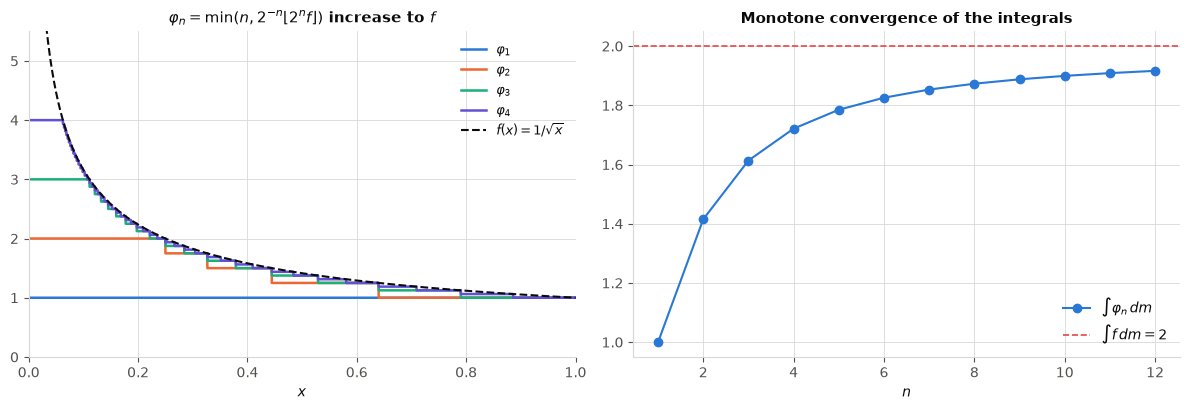

integrals of phi_n: [1.     1.4152 1.6136 1.7213 1.7852 1.8258 1.8533 1.8731]


In [2]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

x = np.linspace(1e-9, 1, 2_000_001)
f = 1 / np.sqrt(x)
phi = lambda n: np.minimum(n, np.floor(2.0 ** n * f) / 2.0 ** n)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
xs = x[::200]
for n, col in zip([1, 2, 3, 4], [BLUE, ORANGE, AQUA, VIOLET]):
    ax.step(xs, phi(n)[::200], where="post", color=col, lw=1.8, label=rf"$\varphi_{n}$")
ax.plot(xs[xs > 0.03], f[::200][xs > 0.03], color=INK, lw=1.5, ls="--", label=r"$f(x) = 1/\sqrt{x}$")
ax.set_xlim(0, 1); ax.set_ylim(0, 5.5); ax.set_xlabel("$x$"); ax.legend(fontsize=9)
ax.set_title(r"$\varphi_n = \min(n, 2^{-n}\lfloor 2^n f \rfloor)$ increase to $f$")

ns = np.arange(1, 13)
dx = x[1] - x[0]
ints = [phi(n).sum() * dx for n in ns]
ax2.plot(ns, ints, "o-", color=BLUE, label=r"$\int \varphi_n \, dm$")
ax2.axhline(2, color=RED, ls="--", lw=1.2, label=r"$\int f\, dm = 2$")
ax2.set_xlabel("$n$"); ax2.legend(loc="lower right")
ax2.set_title("Monotone convergence of the integrals")
plt.tight_layout(); plt.show()
print("integrals of phi_n:", np.round(ints[:8], 4))